# Etap 1 – scenariusz bazowy (bez impulsów)

Segmentacja szeregów czasowych o zachowaniach impulsowych – detekcja zmiany **siły zależności**
między dwoma szeregami. W tym etapie dane są gaussowskie, bez impulsów (punkt odniesienia).

Zawartość notatnika:
1. Generator danych i scenariusze (spadek, wzrost, zmiana znaku, mała zmiana, zmiana stopniowa, brak zmiany H0)
2. Metody klasyczne: Binseg/PELT (`ruptures`, koszt „normal”), CUSUM kowariancji, okno + Pearson, E-Divisive
3. Metryki skuteczności
4. Przykład na jednej realizacji
5. Monte Carlo + tabela zbiorcza + wykresy

**Wymagane biblioteki:** `numpy scipy pandas matplotlib ruptures joblib`

In [3]:
# %pip install numpy scipy pandas matplotlib ruptures joblib

   ---------------------------------------- 0.0/475.9 kB ? eta -:--:--
    --------------------------------------- 10.2/475.9 kB ? eta -:--:--
   -- ------------------------------------ 30.7/475.9 kB 435.7 kB/s eta 0:00:02
   ----- --------------------------------- 71.7/475.9 kB 660.6 kB/s eta 0:00:01
   ------------------- -------------------- 235.5/475.9 kB 1.4 MB/s eta 0:00:01
   ---------------------------------------- 475.9/475.9 kB 2.5 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: C:\Users\majab\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [22]:
import time
import warnings
from dataclasses import dataclass
from functools import lru_cache, partial
from pathlib import Path
from typing import Callable

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import ruptures as rpt
from joblib import Parallel, delayed

warnings.filterwarnings("ignore", message="New behaviour in v1.1.5")  #wyciszenie ostrzeżenia ruptures

#stale
N_REP = 20        # powtórzeń na scenariusz (20 = szybki test, 100 = ok. 5 min na wielu rdzeniach)
N = 1000           # długość szeregu
TAU = 500          # prawdziwy punkt zmiany
MARGIN = 20        # trafienie, gdy |τ̂ − τ| <= MARGIN
SEED = 0
N_JOBS = 1        # liczba procesów (-1 = wszystkie rdzenie); ustaw 1, jeśli równoległość sprawia problemy
USE_PELT = False   # PELT jest wolny – włącz, jeśli chcesz go porównać

RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)

## 1. Generator danych

Sygnał $X$ o kształcie $(n, 2)$; obie składowe mają średnią 0 i wariancję 1, zmienia się **tylko korelacja** $\rho_t$
(metoda nie może „oszukać”, wykrywając zmianę wariancji). Dla każdej chwili $t$:

$$x_1 = z_1, \qquad x_2 = \rho_t z_1 + \sqrt{1-\rho_t^2}\, z_2, \qquad z_1, z_2 \sim N(0,1)$$

co jest równoważne losowaniu z $N\left(0, \begin{bmatrix}1 & \rho_t\\ \rho_t & 1\end{bmatrix}\right)$.

- step: natychmiastowy skok wartości korelacji (z rho_before na rho_after) w wyznaczonym momencie tau.
- none: nrak jakiejkolwiek zmiany (hipoteza zerowa H0); korelacja wynosi stałe rho_before przez cały czas trwania szeregu.
- multi: wiele skoków korelacji występujących w punktach zdefiniowanych w liście taus, przyjmujących wartości z listy rhos.
- gradual: powolne, liniowe przejście między dwiema wartościami korelacji w określonym oknie (szerokości width) wokół punktu tau. w tym przypadku prawdziwy punkt zmiany to po prostu środek tego okna (tau).



In [6]:
CHANGE_KINDS = ("step", "none", "multi", "gradual")

#profil zmiany korelacji - 
#generuje wektor wartości korelacji rho_t dla każdej chwili czasu t oraz za zwróca prawdziwe lokalizacje punktów zmiany
def rho_profile(n, change="step", tau=500, rho_before=0.9, rho_after=0.0,
                taus=None, rhos=None, width=100):
    """zwraca (rho_t, prawdziwe_punkty_zmiany).

    change:
      "step"    – skok rho_before -> rho_after w chwili tau
      "none"    – brak zmiany (H0): rho_t = rho_before w całym szeregu
      "multi"   – kilka skoków: punkty `taus`, wartości `rhos` (len(rhos) == len(taus) + 1)
      "gradual" – liniowe przejście w oknie [tau - width/2, tau + width/2]; prawdziwy punkt = tau
    """
    t = np.arange(n)
    if change == "step":
        rho = np.where(t < tau, rho_before, rho_after)
        cps = [tau]
    elif change == "none":
        rho = np.full(n, rho_before)
        cps = []
    elif change == "multi":
        if taus is None or rhos is None or len(rhos) != len(taus) + 1:
            raise ValueError("change='multi' wymaga taus i rhos, len(rhos) == len(taus) + 1")
        rho = np.asarray(rhos, dtype=float)[np.searchsorted(taus, t, side="right")]
        cps = list(taus)
    elif change == "gradual":
        start, end = tau - width // 2, tau + width // 2
        frac = np.clip((t - start) / max(end - start, 1), 0.0, 1.0)
        rho = rho_before + frac * (rho_after - rho_before)
        cps = [tau]
    else:
        raise ValueError(f"nieznany rodzaj zmiany: {change!r}, dostępne: {CHANGE_KINDS}")

    if np.any(np.abs(rho) >= 1):
        raise ValueError("korelacja musi być w przedziale (-1, 1)")
    return rho, cps


def generate(n=1000, tau=500, rho_before=0.9, rho_after=0.0, change="step",
             noise="none", noise_params=None, seed=None, **change_kwargs):
    """zwraca (X, cps): X ma kształt (n, 2), cps – lista prawdziwych punktów zmiany
    (indeks pierwszej próbki nowego segmentu; pusta lista dla change="none").
    `noise` – miejsce na szum impulsowy z etapu 2; na razie tylko "none" """
    rng = np.random.default_rng(seed)
    rho, cps = rho_profile(n, change, tau, rho_before, rho_after, **change_kwargs)
    z = rng.standard_normal((n, 2))
    X = np.column_stack([z[:, 0], rho * z[:, 0] + np.sqrt(1.0 - rho ** 2) * z[:, 1]])
    if noise != "none":
        raise NotImplementedError("szum impulsowy – etap 2")
    return X, cps


SCENARIOS = {
    "spadek 0.9->0":        dict(change="step", rho_before=0.9, rho_after=0.0),
    "wzrost 0->0.9":        dict(change="step", rho_before=0.0, rho_after=0.9),
    "zmiana znaku":         dict(change="step", rho_before=0.5, rho_after=-0.5),
    "mała zmiana 0.5->0.3": dict(change="step", rho_before=0.5, rho_after=0.3),
    "stopniowa 0.9->0":     dict(change="gradual", rho_before=0.9, rho_after=0.0, width=100),
    "brak zmiany (H0)":     dict(change="none", rho_before=0.5),
}

## 2. Metody klasyczne

Wspólny interfejs dla wszystkich metod: `detect_xxx(X, n_bkps=1, **parameters) -> list[int]` – indeksy początków nowych segmentów. (fcja przyjmuje sygnał X i zwraca listę indeksów określających początki nowych segmentów)
.
Dwa tryby każdej metody:
* `n_bkps=k` – liczba punktów narzucona (czyste porównanie lokalizacji; metoda **zawsze** coś wykryje) TRYB WYMUSZONY,
* `n_bkps=None` – metoda sama decyduje (kara / test / próg); tylko tu mają sens fałszywe alarmy w H0 TRYB AUTOMATYCZNY

In [ ]:
#ruptures: Binseg / PELT z modelem "normal"
#do szybkich testów używamy algorytmu Binseg, ale w razie potrzeby mamy w kodzie gotową, dokładniejszą alternatywę w postaci PELT

def bic_penalty(n, dim=2):
    """kara typu BIC za dodatkowy punkt zmiany:
    nowy segment = dim średnich+ dim(dim+1)/2 elementów kowariancji + położenie punktu
    Heurystyka – uruchomić ten algorytm na scenariuszu, w którym na pewno nie ma żadnej zmiany(H0)"""
    n_params = dim + dim * (dim + 1) // 2 + 1 #liczba parametrow
    return n_params * np.log(n) #kara


#fcja pokmocnicza do usunięcia konca sygnału, jako dodatkowego cps, ktory jest dodawany przez biblioteke ruptures
def _strip_end(bkps, n):
    return [b for b in bkps if b < n]


def detect_binseg_normal(X, n_bkps=1, pen=None, min_size=30, jump=1):
    """jump=1 – sprawdzamy każdą próbkę. przy jump=5 kandydatami są tylko wielokrotności 5,
    a skoro tau = 500 też nią jest, metoda dostawałaby sztucznie zerowy błąd."""
    algo = rpt.Binseg(model="normal", min_size=min_size, jump=jump).fit(X)
    if n_bkps is not None:
        return _strip_end(algo.predict(n_bkps=n_bkps), len(X))
    return _strip_end(algo.predict(pen=bic_penalty(len(X)) if pen is None else pen), len(X))


def detect_pelt_normal(X, pen=None, min_size=30, jump=5, n_bkps=None):
    """PELT zawsze działa z karą. Ponieważ jest on bardzo wolny, ustawiamy 
    tu przeszukiwanie co 5 próbek (jump=5), co przyspiesza działanie kosztem lekkiego zaokrąglania wyniku
    (przy tau = 500 zaniża błąd)"""
    algo = rpt.Pelt(model="normal", min_size=min_size, jump=jump).fit(X)
    return _strip_end(algo.predict(pen=bic_penalty(len(X)) if pen is None else pen), len(X))


#pomocnicza segmentacja binarna

def _binary_segmentation(X, single_split, n_bkps, accept, min_size):
    """single_split(X_seg) -> (k, stat), aby w tym segmencie znaleźć jeden,
    najbardziej ewidentny punkt, w którym statystyka testowa ma najwyższą wartość.
    n_bkps podane: dzielimy segment z największą statystyką; 
    n_bkps=None: dzielimy, dopóki accept(stat, długość) jest prawdziwe"""
    segments = [(0, len(X))]
    cps = []
    while True: #tniemy sygnal
        best = None
        for a, b in segments:
            if b - a < 2 * min_size: #blokada przed tworzeniem krotkich kawalkow (gdy segment< 2 razy rozm. min, to przeskakujemy)
                continue
            k, stat = single_split(X[a:b]) #fcja maat, ktora wskazuje lokalne maksimum i stat - ocena punktowa
            if k is not None and (best is None or stat > best[2]): #ze wszystkich fragmentow, algorytm zapamiętuje tylko ten jeden,
                #który ma najsilniejszy (najwyżej punktowany) szczyt zmiany
                best = (a, b, stat, a + k)
        if best is None:
            break
        a, b, stat, cp = best
        if n_bkps is None and not accept(stat, b - a):
            break
        cps.append(cp)
        segments.remove((a, b))
        segments += [(a, cp), (cp, b)]
        if n_bkps is not None and len(cps) >= n_bkps:
            break
    return sorted(cps)


#CUSUM dla macierzy kowariancji (wzory z literaturuy)

def cusum_cov_statistic(X, min_size=30):
    """Q_k = (1/n) S_k^T Sigma^{-1} S_k,  S_k = sum_{t<k} (Y_t - mean(Y)),  Y_t = (x1^2, x1*x2, x2^2).
    Zmiana kowariancji = zmiana średniej Y_t. Sigma – zwykła kowariancja Y_t (dane niezależne w czasie). 
    detekcja zmiany kowariancji (zależności) w pierwotnym sygnale sprowadza się do wykrycia zmiany wartości 
    średniej w specjalnie przekształconym sygnale Y_t."""
    n = len(X)
    x1, x2 = X[:, 0], X[:, 1] #rozdzielenie mac X na dwa wektory (sygnał X i Y)
    Y = np.column_stack([x1 * x1, x1 * x2, x2 * x2]) #^2
    S = np.vstack([np.zeros(3), np.cumsum(Y - Y.mean(axis=0), axis=0)])[:n]
    #pinv - pseudoodwrotność Moore'a-Penrose'a 
    #to statystyczny czynnik ważący (skalujący), który zapobiega dominacji jednej silnej zmiennej nad pozostałymi
    Sigma_inv = np.linalg.pinv(np.cov(Y, rowvar=False))
    #zoptymalizowana wektorowa notacja Einsteina
    Q = np.einsum("ij,jk,ik->i", S, Sigma_inv, S) / n
    #wyzerowuje do wartości Not a Number) początkowy i końcowy fragment obliczonej statystyki Q
    Q[:min_size] = np.nan
    Q[n - min_size + 1:] = np.nan
    return Q

#wartość krytyczna
@lru_cache(maxsize=None) #ciężka praca wykonywana jest tylko  raz– każde następne wywołanie funkcji w pętli Monte Carlo nie uruchamia już symulacji, tylko  wyciąga gotowy próg z pamięci podręcznej
def cusum_critical_value(dim=3, alpha=0.05, n_sim=5000, grid=1000, seed=12345):
    """kwantyl 1-alpha rozkładu sup_u sum_i B_i(u)^2 (B_i – mosty Browna) – graniczny rozkład
    max_k Q_k przy braku zmiany. liczony symulacyjnie (raz, potem z pamięci podręcznej)."""
    rng = np.random.default_rng(seed)
    u = np.arange(1, grid + 1) / grid
    sups = np.empty(n_sim)
    for i in range(n_sim):
        W = np.cumsum(rng.standard_normal((grid, dim)), axis=0) / np.sqrt(grid)
        B = W - u[:, None] * W[-1]
        sups[i] = np.max(np.sum(B ** 2, axis=1))
    return float(np.quantile(sups, 1 - alpha))


def detect_cusum_cov(X, n_bkps=1, alpha=0.05, min_size=30):
    def single(seg):
        Q = cusum_cov_statistic(seg, min_size)
        if np.all(np.isnan(Q)):
            return None, -np.inf
        k = int(np.nanargmax(Q)) #szuka najwyzszego szczytu
        return k, float(Q[k]) #zwraca lokalizację i punktację

    #wyciągamy z pamięci RAM wyliczoną w poprzednim kroku statystyczną wartość krytyczną
    crit = cusum_critical_value(3, alpha)
    return _binary_segmentation(X, single, n_bkps, lambda stat, _: stat > crit, min_size)


#0kno przesuwne + korelacja Pearsona
def window_pearson_statistic(X, width=100):
    """|atanh(r_lewe) - atanh(r_prawe)| / sqrt(2/(width-3)) – porównanie korelacji w oknach
    [t-width, t) i [t, t+width) (atanh - transformacja Fishera). metoda bierze okno "przeszłe" i okno "przyszłe",
    liczy w nich korelację, a następnie sprawdza różnicę między nimi.ponieważ współczynnik korelacji ma specyficzny,
    ograniczony rozkład, zastosowłysmy atanh, ktory pozwala przekształcić korelację tak, by jej różnice można było 
    badać standardowymi metodami statystycznymi"""
    n = len(X)
    x, y = X[:, 0], X[:, 1]
    c = lambda v: np.concatenate([[0.0], np.cumsum(v)])
    sx, sy, sxx, syy, sxy = c(x), c(y), c(x * x), c(y * y), c(x * y)

    def corr(a, b):  #korelacja w oknie [a, b) z sum skumulowanych
        m = b - a
        mx, my = (sx[b] - sx[a]) / m, (sy[b] - sy[a]) / m
        vx = (sxx[b] - sxx[a]) / m - mx ** 2
        vy = (syy[b] - syy[a]) / m - my ** 2
        return ((sxy[b] - sxy[a]) / m - mx * my) / np.sqrt(vx * vy)

    stat = np.full(n, np.nan)
    t = np.arange(width, n - width + 1)
    r_left = np.clip(corr(t - width, t), -0.999999, 0.999999)
    r_right = np.clip(corr(t, t + width), -0.999999, 0.999999)
    stat[t] = np.abs(np.arctanh(r_left) - np.arctanh(r_right)) / np.sqrt(2.0 / (width - 3))
    return stat


def detect_window_pearson(X, n_bkps=1, width=100, threshold=None):
    """n_bkps podane: tyle najwyższych szczytów (oddalonych o >= width);
    n_bkps=None: szczyty powyżej progu (domyślnie 4.0 – do skalibrowania na H0)."""
    stat = window_pearson_statistic(X, width)
    threshold = 4.0 if threshold is None else threshold
    s = np.nan_to_num(stat, nan=-np.inf)
    cps = []
    while n_bkps is None or len(cps) < n_bkps:
        k = int(np.argmax(s))
        if not np.isfinite(s[k]) or (n_bkps is None and s[k] <= threshold):
            break
        cps.append(k)
        s[max(0, k - width):k + width] = -np.inf
    return sorted(cps)


# ---------- 2.4 E-Divisive / energy distance (Matteson & James 2014) ----------

#def energy_statistic(X, min_size=30, alpha=1.0):
   # """Q_k = k(n-k)/n * E_k, E_k – energy distance między X[:k] a X[k:],
    #dla wszystkich k naraz w O(n^2) (dwuwymiarowe sumy prefiksowe macierzy odległości)."""
    #n = len(X)
    #D = np.sqrt(np.sum((X[:, None, :] - X[None, :, :]) ** 2, axis=-1)) ** alpha
    # P = np.zeros((n + 1, n + 1))
    # P[1:, 1:] = D.cumsum(0).cumsum(1)          # P[a, b] = suma D[:a, :b]
    # total = P[n, n]
    # k = np.arange(min_size, n - min_size + 1)
    # left = P[k, k]
    # cross = P[k, n] - P[k, k]
    # right = total - left - 2 * cross
    # m = n - k
    # E = 2 * cross / (k * m) - left / (k * (k - 1)) - right / (m * (m - 1))
    # Q = np.full(n, np.nan)
    # Q[k] = k * m / n * E
    # return Q


# def detect_edivisive(X, n_bkps=1, min_size=30):
#     """Tylko tryb z n_bkps – oryginalny test permutacyjny jest zbyt wolny do Monte Carlo."""
#     if n_bkps is None:
#         raise ValueError("detect_edivisive wymaga n_bkps")

#     def single(seg):
#         Q = energy_statistic(seg, min_size)
#         if np.all(np.isnan(Q)):
#             return None, -np.inf
#         k = int(np.nanargmax(Q))
#         return k, float(Q[k])

#     return _binary_segmentation(X, single, n_bkps, None, min_size)

## 3. Metryki
* **loc_error** – odległość prawdziwego punktu od najbliższego wykrytego (NaN, gdy nic nie wykryto),
* **hit** – czy każdy prawdziwy punkt ma wykryty punkt w odległości ≤ `MARGIN`,
* **false_pos** – wykryte punkty dalej niż `MARGIN` od prawdziwych,
* **any_detect** – czy coś wykryto (w scenariuszu H0 = fałszywy alarm).

In [ ]:
def evaluate(cps_hat, cps_true, margin=20):
    hat = np.asarray(cps_hat, dtype=float)
    true = np.asarray(cps_true, dtype=float)
    if len(true) and len(hat):
        dist = np.abs(true[:, None] - hat[None, :])#prawdziwe x wykryte
        loc_error = float(dist.min(axis=1).mean())
        hit = float(np.all(dist.min(axis=1) <= margin))
        false_pos = int(np.sum(dist.min(axis=0) > margin))
    else:
        loc_error = np.nan
        hit = 0.0 if len(true) else np.nan
        false_pos = len(hat)
    return dict(loc_error=loc_error, hit=hit, n_detected=len(hat),
                false_pos=false_pos, any_detect=len(hat) > 0)


def mean_ci(x, z=1.96):
    """średnia i połowa szerokości 95% przedziału ufności"""
    x = np.asarray(x, dtype=float)
    x = x[~np.isnan(x)] #wyrzucenie NaN
    if len(x) < 2:
        return (float(x.mean()) if len(x) else np.nan), np.nan
    return float(x.mean()), float(z * x.std(ddof=1) / np.sqrt(len(x))) 
#Z * przez odchylenie standardowe próbki/  przez pierwiastek z liczby prób

## 4. Lista porównywanych metod

In [19]:
@dataclass
class Detector:
    name: str
    fn: Callable
    forced: bool  # True = liczba punktów narzucona (n_bkps) – metoda zawsze coś wykrywa


DETECTORS = [
    # liczba punktów narzucona – czyste porównanie lokalizacji
    Detector("Binseg normal (n_bkps=1)", partial(detect_binseg_normal, n_bkps=1), forced=True),
    Detector("CUSUM kow. (n_bkps=1)", partial(detect_cusum_cov, n_bkps=1), forced=True),
    Detector("Okno+Pearson (n_bkps=1)", partial(detect_window_pearson, n_bkps=1), forced=True),
    #Detector("E-Divisive (n_bkps=1)", partial(detect_edivisive, n_bkps=1), forced=True),
    # liczba punktów wybierana przez metodę – tu mierzymy fałszywe alarmy
    Detector("Binseg normal (kara BIC)", partial(detect_binseg_normal, n_bkps=None), forced=False),
    Detector("CUSUM kow. (test 5%)", partial(detect_cusum_cov, n_bkps=None, alpha=0.05), forced=False),
    Detector("Okno+Pearson (próg 4)", partial(detect_window_pearson, n_bkps=None), forced=False),
]
if USE_PELT:
    DETECTORS.append(Detector("PELT normal (kara BIC, jump=5)", detect_pelt_normal, forced=False))

## 5. Przykład na jednej realizacji (spadek korelacji 0,9 → 0 w t = 500)

Binseg normal (n_bkps=1)         [501]
CUSUM kow. (n_bkps=1)            [503]
Okno+Pearson (n_bkps=1)          [500]
Binseg normal (kara BIC)         [501]
CUSUM kow. (test 5%)             [263, 503]
Okno+Pearson (próg 4)            [500]


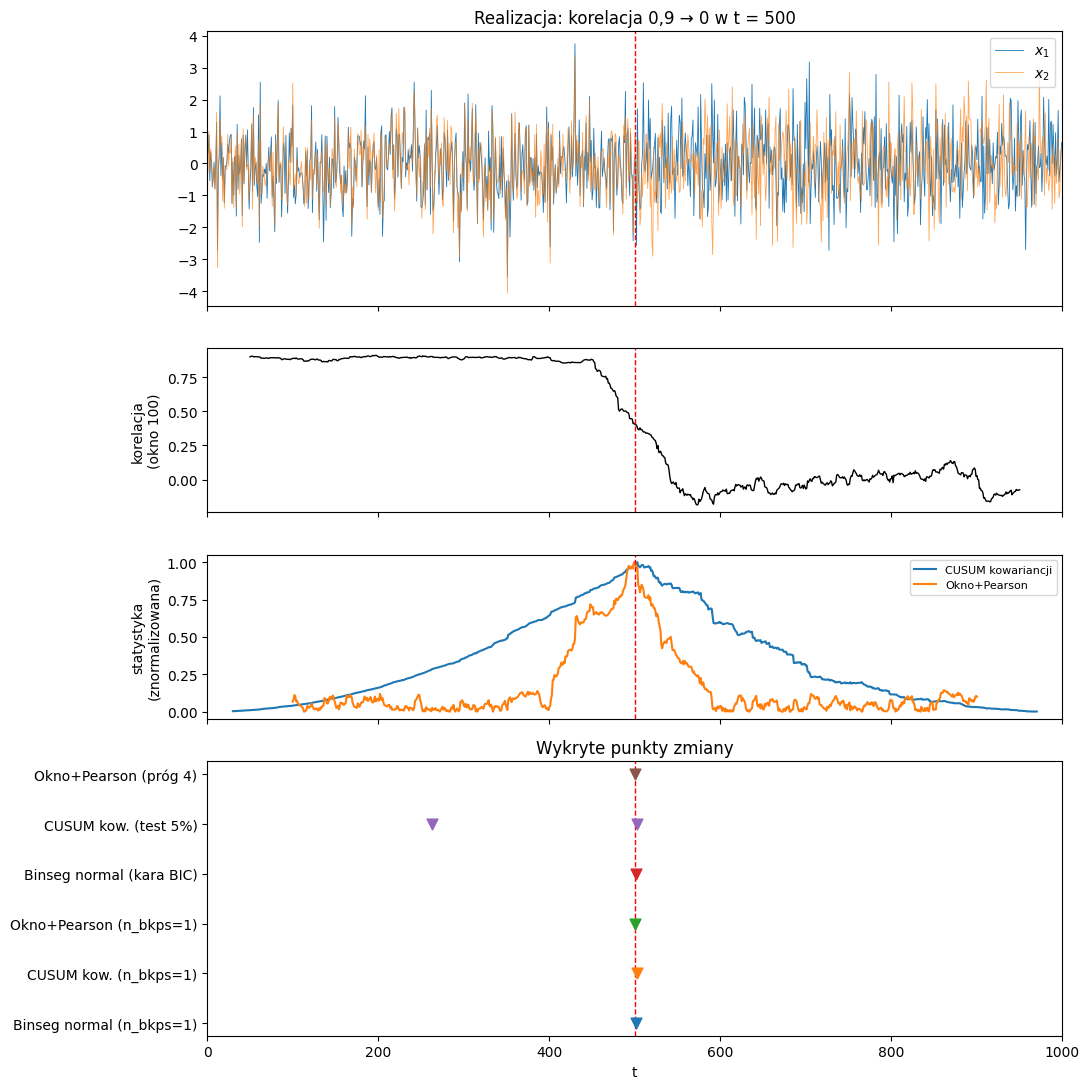

In [20]:
def rolling_corr(X, width):
    return pd.Series(X[:, 0]).rolling(width, center=True).corr(pd.Series(X[:, 1])).to_numpy()


X, cps_true = generate(n=N, tau=TAU, seed=1, **SCENARIOS["spadek 0.9->0"])
found = {d.name: d.fn(X) for d in DETECTORS}
for name, cps in found.items():
    print(f"{name:<32} {cps}")

width = 100
fig, axes = plt.subplots(4, 1, figsize=(11, 11), sharex=True,
                         gridspec_kw=dict(height_ratios=[2, 1.2, 1.2, 2]))
axes[0].plot(X[:, 0], lw=0.6, label="$x_1$")
axes[0].plot(X[:, 1], lw=0.6, alpha=0.7, label="$x_2$")
axes[0].set_title(f"Realizacja: korelacja 0,9 → 0 w t = {TAU}")
axes[0].legend(loc="upper right")

axes[1].plot(rolling_corr(X, width), color="k", lw=1)
axes[1].set_ylabel(f"korelacja\n(okno {width})")

for stat, label in [(cusum_cov_statistic(X), "CUSUM kowariancji"),
                    #(energy_statistic(X), "E-Divisive"),
                    (window_pearson_statistic(X, width), "Okno+Pearson")]:
    axes[2].plot(stat / np.nanmax(stat), label=label)
axes[2].set_ylabel("statystyka\n(znormalizowana)")
axes[2].legend(loc="upper right", fontsize=8)

for i, (name, cps) in enumerate(found.items()):
    axes[3].scatter(cps, [i] * len(cps), marker="v", s=60, zorder=3)
axes[3].set_yticks(range(len(found)), list(found))
axes[3].set_xlabel("t")
axes[3].set_title("Wykryte punkty zmiany")
for a in axes:
    for c in cps_true:
        a.axvline(c, color="red", ls="--", lw=1)
axes[3].set_xlim(0, N)
fig.tight_layout()
fig.savefig(RESULTS / "etap1_przyklad.png", dpi=130)
plt.show()

## 6. Monte Carlo
Dla każdego scenariusza `N_REP` symulacji; wszystkie metody dostają **te same dane** (to samo ziarno).
Jeden wiersz wyniku = jedna symulacja × jedna metoda.

In [23]:
def one_simulation(s_name, s_params, data_seed, rep, detectors, n, tau, margin):
    import warnings
    warnings.filterwarnings("ignore", message="New behaviour in v1.1.5")  # w procesach roboczych
    X, cps_true = generate(n=n, tau=tau, seed=data_seed, **s_params)
    rows = []
    for det in detectors:
        t = time.perf_counter()
        cps_hat = det.fn(X)
        elapsed = time.perf_counter() - t
        rows.append(dict(scenario=s_name, method=det.name, forced=det.forced, rep=rep,
                         cps_true=cps_true, cps_hat=cps_hat, time_s=elapsed,
                         **evaluate(cps_hat, cps_true, margin)))
    return rows


def run_monte_carlo(scenarios, detectors, n_rep=100, n=1000, tau=500, margin=20, seed=0, n_jobs=-1):
    rows = []
    for s_idx, (s_name, s_params) in enumerate(scenarios.items()):
        t0 = time.perf_counter()
        results = Parallel(n_jobs=n_jobs)(
            delayed(one_simulation)(s_name, s_params, seed + 100_000 * s_idx + rep, rep,
                                    detectors, n, tau, margin)
            for rep in range(n_rep))
        for r in results:
            rows += r
        print(f"  {s_name:<24} {n_rep} powt. w {time.perf_counter() - t0:.1f} s")
    return pd.DataFrame(rows)


cusum_critical_value(3, 0.05)  # policz raz wartość krytyczną przed pętlą
print(f"Monte Carlo: {len(SCENARIOS)} scenariuszy x {len(DETECTORS)} metod x {N_REP} powt.")
raw = run_monte_carlo(SCENARIOS, DETECTORS, n_rep=N_REP, n=N, tau=TAU,
                      margin=MARGIN, seed=SEED, n_jobs=N_JOBS)
raw.to_csv(RESULTS / "etap1_raw.csv", index=False)
raw.head()

Monte Carlo: 6 scenariuszy x 6 metod x 20 powt.
  spadek 0.9->0            20 powt. w 4.2 s
  wzrost 0->0.9            20 powt. w 4.1 s
  zmiana znaku             20 powt. w 4.2 s
  mała zmiana 0.5->0.3     20 powt. w 3.2 s
  stopniowa 0.9->0         20 powt. w 4.1 s
  brak zmiany (H0)         20 powt. w 3.6 s


,scenario,method,forced,rep,cps_true,cps_hat,time_s,loc_error,hit,n_detected,false_pos,any_detect
0,spadek 0.9->0,Binseg normal (n_bkps=1),True,0,[500],[502],0.134038,2.0,1.0,1,0,True
1,spadek 0.9->0,CUSUM kow. (n_bkps=1),True,0,[500],[510],0.000479,10.0,1.0,1,0,True
2,spadek 0.9->0,Okno+Pearson (n_bkps=1),True,0,[500],[496],0.000210,4.0,1.0,1,0,True
3,spadek 0.9->0,Binseg normal (kara BIC),False,0,[500],[502],0.099157,2.0,1.0,1,0,True
4,spadek 0.9->0,CUSUM kow. (test 5%),False,0,[500],[510],0.000828,10.0,1.0,1,0,True


## 7. Tabela zbiorcza
Kolumny „±” to połowy 95% przedziałów ufności. Fałszywe alarmy liczone tylko w scenariuszu H0 i tylko dla
metod bez narzuconej liczby punktów. Błąd lokalizacji jest liczony tylko z symulacji, w których metoda
coś wykryła – przy metodach z karą/testem czytaj go razem z hit rate.

Uwaga: przy `N_JOBS != 1` czasy są zawyżone (procesy konkurują o procesor) – do porównania szybkości ustaw `N_JOBS = 1`.

In [27]:
def summarize(df):
    out = []
    for (scen, method), g in df.groupby(["scenario", "method"], sort=False):
        is_h0 = all(len(c) == 0 for c in g["cps_true"])
        err_mean, err_ci = mean_ci(g["loc_error"])
        hit_mean, hit_ci = mean_ci(g["hit"])
        fa_mean, fa_ci = mean_ci(g["any_detect"].astype(float))
        forced = bool(g["forced"].iloc[0])
        out.append({
            "scenariusz": scen,
            "metoda": method,
            "mediana |τ̂−τ|": np.nan if is_h0 else g["loc_error"].median(),
            "średnia |τ̂−τ|": np.nan if is_h0 else err_mean,
            "± (95%)": np.nan if is_h0 else err_ci,
            "hit rate": np.nan if is_h0 else hit_mean,
            "hit ± (95%)": np.nan if is_h0 else hit_ci,
            "fałszywe alarmy H0": fa_mean if (is_h0 and not forced) else np.nan,
            "FA ± (95%)": fa_ci if (is_h0 and not forced) else np.nan,
            "śr. l. fałszywych pkt": np.nan if forced else g["false_pos"].mean(),
            "czas [ms]": 1000 * g["time_s"].mean(),
        })
    return pd.DataFrame(out)


summary = summarize(raw)
summary.to_csv(RESULTS / "etap1_summary.csv", index=False, float_format="%.4g")
summary

C:\Users\majab\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


,scenariusz,metoda,mediana |τ̂−τ|,średnia |τ̂−τ|,± (95%),hit rate,hit ± (95%),fałszywe alarmy H0,FA ± (95%),śr. l. fałszywych pkt,czas [ms]
0,spadek 0.9->0,Binseg normal (n_bkps=1),1.0,1.750000,0.931068,1.00,0.000000,NaN,NaN,NaN,105.864385
1,spadek 0.9->0,CUSUM kow. (n_bkps=1),2.0,4.200000,2.317359,1.00,0.000000,NaN,NaN,NaN,0.435820
2,spadek 0.9->0,Okno+Pearson (n_bkps=1),3.5,4.900000,2.252317,1.00,0.000000,NaN,NaN,NaN,0.207765
3,spadek 0.9->0,Binseg normal (kara BIC),1.0,1.750000,0.931068,1.00,0.000000,NaN,NaN,0.00,101.389640
4,spadek 0.9->0,CUSUM kow. (test 5%),2.0,3.800000,1.894963,1.00,0.000000,NaN,NaN,0.25,1.053065
5,spadek 0.9->0,Okno+Pearson (próg 4),3.5,4.900000,2.252317,1.00,0.000000,NaN,NaN,0.00,0.204585
6,wzrost 0->0.9,Binseg normal (n_bkps=1),0.0,0.900000,0.680451,1.00,0.000000,NaN,NaN,NaN,103.505020
7,wzrost 0->0.9,CUSUM kow. (n_bkps=1),0.5,2.100000,1.230609,1.00,0.000000,NaN,NaN,NaN,0.399730
8,wzrost 0->0.9,Okno+Pearson (n_bkps=1),1.0,2.800000,2.003867,1.00,0.000000,NaN,NaN,NaN,0.198225
9,wzrost 0->0.9,Binseg normal (kara BIC),0.0,0.900000,0.680451,1.00,0.000000,NaN,NaN,0.00,101.399835


## 8. Wykresy porównawcze

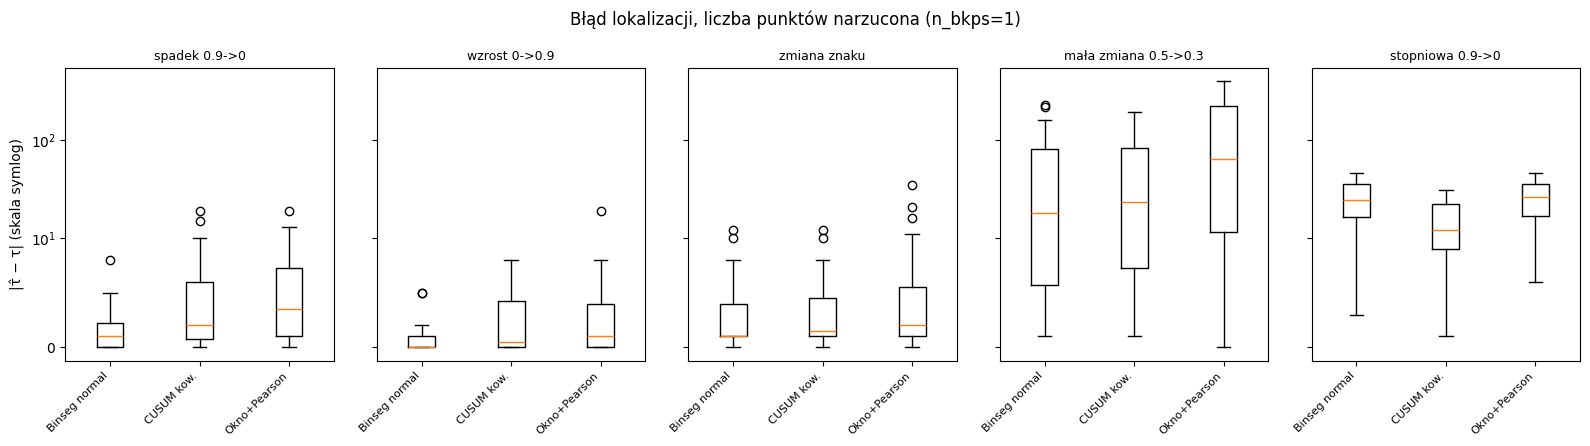

In [26]:
# 8.1 Błąd lokalizacji – metody z n_bkps=1, scenariusze ze zmianą
forced = raw[raw["forced"] & raw["loc_error"].notna()]
scen = [s for s in raw["scenario"].unique() if s in forced["scenario"].unique()]
methods = list(forced["method"].unique())
fig, axes = plt.subplots(1, len(scen), figsize=(3.2 * len(scen), 4.5), sharey=True)
for ax, s in zip(np.atleast_1d(axes), scen):
    data = [forced[(forced.scenario == s) & (forced.method == m)]["loc_error"] for m in methods]
    ax.boxplot(data)
    ax.set_xticks(range(1, len(methods) + 1), [m.split(" (")[0] for m in methods],
                  rotation=45, ha="right", fontsize=8)
    ax.set_title(s, fontsize=9)
    ax.set_yscale("symlog", linthresh=10)
np.atleast_1d(axes)[0].set_ylabel("|τ̂ − τ| (skala symlog)")
fig.suptitle("Błąd lokalizacji, liczba punktów narzucona (n_bkps=1)")
fig.tight_layout()
fig.savefig(RESULTS / "etap1_blad_lokalizacji.png", dpi=130)
plt.show()

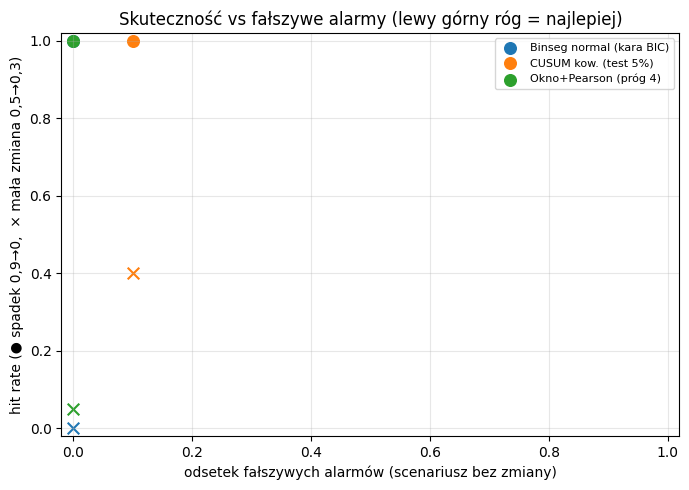

In [29]:
# 8.2 Skuteczność vs fałszywe alarmy – metody z karą / testem
free = summary[summary["metoda"].isin([d.name for d in DETECTORS if not d.forced])]
fa = free.dropna(subset=["fałszywe alarmy H0"]).set_index("metoda")["fałszywe alarmy H0"]
hit = free[free["scenariusz"] == "spadek 0.9->0"].set_index("metoda")["hit rate"]
small = free[free["scenariusz"] == "mała zmiana 0.5->0.3"].set_index("metoda")["hit rate"]

fig, ax = plt.subplots(figsize=(7, 5))
for m in fa.index:
    ax.scatter(fa[m], hit.get(m, np.nan), s=70, label=m)
    ax.scatter(fa[m], small.get(m, np.nan), s=70, marker="x",
               color=ax.collections[-1].get_facecolor())
ax.set_xlabel("odsetek fałszywych alarmów (scenariusz bez zmiany)")
ax.set_ylabel("hit rate (● spadek 0,9→0,  × mała zmiana 0,5→0,3)")
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.02, 1.02)
ax.grid(alpha=0.3)
ax.legend(fontsize=8, loc="upper right")
ax.set_title("Skuteczność vs fałszywe alarmy (lewy górny róg = najlepiej)")
fig.tight_layout()
fig.savefig(RESULTS / "etap1_skutecznosc_vs_FA.png", dpi=130)
plt.show()